In [2]:
import sys
import os
import math

from matplotlib import pyplot as plt, colors, patches

import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.cross_decomposition import CCA


sys.path.append(os.path.join(os.getcwd(), '../import'))

# noinspection PyUnresolvedReferences
from utils import read_utils
# noinspection PyUnresolvedReferences
from utils import plot_utils
# noinspection PyUnresolvedReferences
from utils import train_utils

In [3]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/Work/ZimmerLab/MSc_Thesis/Workspace/DataSpell/worm-2025-fieseler/data_exploration/../import/utils/train_utils.py'>

In [4]:
# read_ids = [0, 4, 5, 6, 27, 30, 31, 32, 33]
read_ids = list(range(0, 33 + 1))
plot_id = 4

dims = 2

selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

In [5]:
path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gcamp')
file_ids, filenames, continuous_behaviors, discrete_states, eigenworms, kymographs, traces = read_utils.get_data(path, read_ids)

for i in range(len(filenames)):
	mask = eigenworms[i].notna().all(axis=1)
	#continuous_behaviors[i] = continuous_behaviors[i][mask]
	discrete_states[i] = discrete_states[i][mask]
	eigenworms[i] = eigenworms[i][mask]
	traces[i] = traces[i][mask]

	#kymographs[i] = kymographs[i][mask]
	#filenames[i] = filenames[i][mask]

# discrete_states = [ds[selection_bhl] for ds in discrete_states]

In [6]:
(modes_manifold, modes_manifold_b,
 recos_manifold, recos_manifold_b,
 loads_cca_man, loads_cca_man_b,
 vars_expl_man, vars_expl_man_rs) = train_utils.get_manifolds(traces,
																[ds[selection_bhl] for ds in discrete_states],
																n_cc=dims, n_pc=5)

In [7]:
# plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids], modes_manifold, [ds[['FWD'] + selection_bhl] for ds in discrete_states], vars_expl_man, vars_expl_man_rs,
# 						  top_space=3.5)

In [8]:
traces_residuals = [pd.DataFrame(data=t.values - t_man.values, columns=t.columns) for t, t_man in zip(traces, recos_manifold)]

In [9]:
n = eigenworms[file_ids.index(plot_id)].values.shape[1]

modes_concrete, modes_concrete_b = list(), list()
recos_concrete, recos_concrete_b = list(), list()
loads_cca_con, loads_cca_con_b = list(), list()
vars_expl_con, vars_expl_con_rs = list(), list()  # rs in this case: variance explained with respect to the manifold-residual data
for trace, trace_residual, ew in zip(traces, traces_residuals, eigenworms):
	cca = CCA(n_components=n, scale=True)

	trace_residual_reduced, ew_reduced = cca.fit_transform(trace_residual.values, ew.values)
	trace_residual_reconstructed, ew_reconstructed = cca.inverse_transform(trace_residual_reduced, ew_reduced)

	modes_concrete.append(pd.DataFrame(data=trace_residual_reduced, columns=[f'CC{i + 1}' for i in range(n)]))
	recos_concrete.append(pd.DataFrame(data=trace_residual_reconstructed, columns=trace_residual.columns))

	loads_cca_con.append(cca.x_loadings_)
	loads_cca_con_b.append(cca.y_loadings_)

	var_ratio = train_utils.get_variance_explained(trace_residual_reconstructed, trace)
	var_ratio_rs = train_utils.get_variance_explained(trace_residual_reconstructed, trace_residual)
	vars_expl_con.append(var_ratio)
	vars_expl_con_rs.append(var_ratio_rs)

5.9% (10.3%)


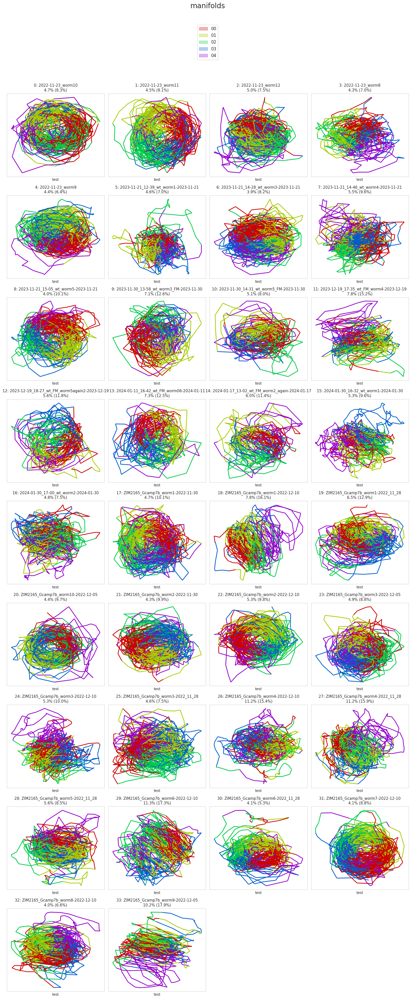

In [10]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids], modes_concrete, eigenworms, vars_expl_con, vars_expl_con_rs,
						  top_space=3.5)

In [11]:
fwd_indices = [np.where(ds['FWD'].values == 1) for ds in discrete_states]
rev_indices = [np.where(ds['REV'].values == 1) for ds in discrete_states]

traces_fwd = [pd.DataFrame(data=trace.values[fwd_index], columns=trace.columns) for trace, fwd_index in zip(traces, fwd_indices)]
traces_rev = [pd.DataFrame(data=trace.values[rev_index], columns=trace.columns) for trace, rev_index in zip(traces, rev_indices)]

traces_residuals_fwd = [pd.DataFrame(data=trace.values[fwd_index], columns=trace.columns) for trace, fwd_index in zip(traces_residuals, fwd_indices)]
traces_residuals_rev = [pd.DataFrame(data=trace.values[rev_index], columns=trace.columns) for trace, rev_index in zip(traces_residuals, rev_indices)]

eigenworms_fwd = [pd.DataFrame(data=ew.values[fwd_index], columns=ew.columns) for ew, fwd_index in zip(eigenworms, fwd_indices)]
eigenworms_rev = [pd.DataFrame(data=ew.values[rev_index], columns=ew.columns) for ew, rev_index in zip(eigenworms, rev_indices)]

discrete_states_fwd = [pd.DataFrame(data=ds.values[fwd_index], columns=ds.columns) for ds, fwd_index in zip(discrete_states, fwd_indices)]
discrete_states_rev = [pd.DataFrame(data=ds.values[rev_index], columns=ds.columns) for ds, rev_index in zip(discrete_states, rev_indices)]

In [12]:
modes_concrete_fwd, modes_concrete_b_fwd = list(), list()
recos_concrete_fwd, recos_concrete_b_fwd = list(), list()
loads_cca_con_fwd, loads_cca_con_b_fwd = list(), list()
vars_expl_con_fwd, vars_expl_con_rs_fwd = list(), list()  # rs in this case: variance explained with respect to the manifold-residual data
for trace, trace_residual, ew in zip(traces_fwd, traces_residuals_fwd, eigenworms_fwd):
	cca = CCA(n_components=n, scale=True)

	trace_residual_reduced, ew_reduced = cca.fit_transform(trace_residual.values, ew.values)
	trace_residual_reconstructed, ew_reconstructed = cca.inverse_transform(trace_residual_reduced, ew_reduced)

	modes_concrete_fwd.append(pd.DataFrame(data=trace_residual_reduced, columns=[f'CC{i + 1}' for i in range(n)]))
	recos_concrete_fwd.append(pd.DataFrame(data=trace_residual_reconstructed, columns=trace_residual.columns))

	loads_cca_con_fwd.append(cca.x_loadings_)
	loads_cca_con_b_fwd.append(cca.y_loadings_)

	var_ratio = train_utils.get_variance_explained(trace_residual_reconstructed, trace)
	var_ratio_rs = train_utils.get_variance_explained(trace_residual_reconstructed, trace_residual)
	vars_expl_con_fwd.append(var_ratio)
	vars_expl_con_rs_fwd.append(var_ratio_rs)

/home/julian-zim/.venv/hgm/lib/python3.12/site-packages/sklearn/cross_decomposition/_pls.py:104: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


12.3% (13.7%)


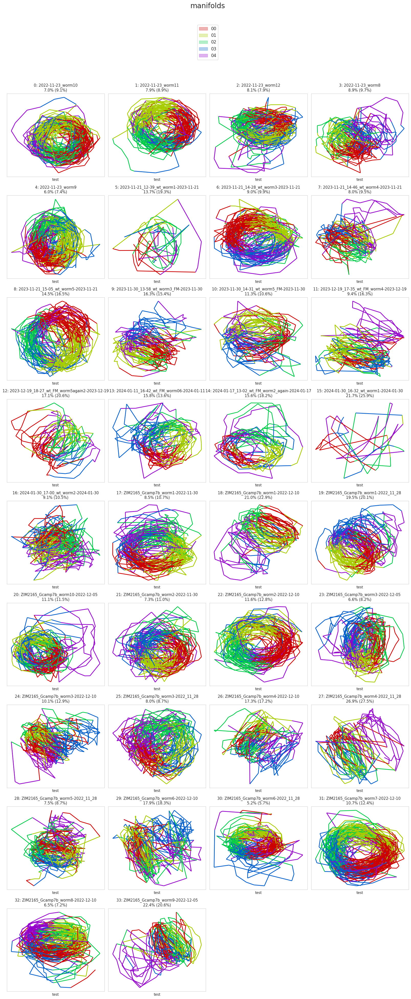

In [13]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids], modes_concrete_fwd, eigenworms_fwd, vars_expl_con_fwd, vars_expl_con_rs_fwd,
						  top_space=3.5)

In [14]:
modes_concrete_rev, modes_concrete_b_rev = list(), list()
recos_concrete_rev, recos_concrete_b_rev = list(), list()
loads_cca_con_rev, loads_cca_con_b_rev = list(), list()
vars_expl_con_rev, vars_expl_con_rs_rev = list(), list()  # rs in this case: variance explained with respect to the manifold-residual data
for trace, trace_residual, ew in zip(traces_rev, traces_residuals_rev, eigenworms_rev):
	cca = CCA(n_components=n, scale=True)

	trace_residual_reduced, ew_reduced = cca.fit_transform(trace_residual.values, ew.values)
	trace_residual_reconstructed, ew_reconstructed = cca.inverse_transform(trace_residual_reduced, ew_reduced)

	modes_concrete_rev.append(pd.DataFrame(data=trace_residual_reduced, columns=[f'CC{i + 1}' for i in range(n)]))
	recos_concrete_rev.append(pd.DataFrame(data=trace_residual_reconstructed, columns=trace_residual.columns))

	loads_cca_con_rev.append(cca.x_loadings_)
	loads_cca_con_b_rev.append(cca.y_loadings_)

	var_ratio = train_utils.get_variance_explained(trace_residual_reconstructed, trace)
	var_ratio_rs = train_utils.get_variance_explained(trace_residual_reconstructed, trace_residual)
	vars_expl_con_rev.append(var_ratio)
	vars_expl_con_rs_rev.append(var_ratio_rs)

/home/julian-zim/.venv/hgm/lib/python3.12/site-packages/sklearn/cross_decomposition/_pls.py:104: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)
/home/julian-zim/.venv/hgm/lib/python3.12/site-packages/sklearn/cross_decomposition/_pls.py:104: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


7.3% (11.8%)


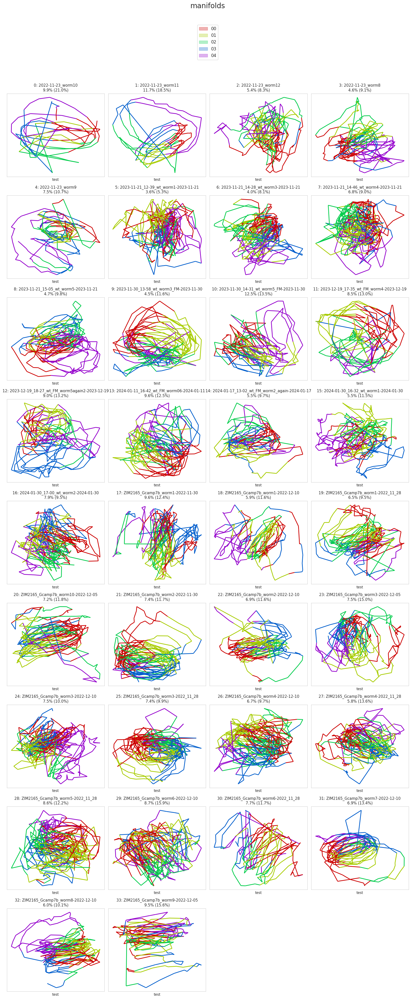

In [15]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids], modes_concrete_rev, eigenworms_rev, vars_expl_con_rev, vars_expl_con_rs_rev,
						  top_space=3.5)